In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

In [30]:
from google.colab import files
uploaded = files.upload()

Saving creditcard.csv to creditcard (1).csv


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


In [32]:
df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

   

In [33]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum().sum())

Dataset Shape: (284807, 31)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20

Class
0    284315
1       492
Name: count, dtype: int64


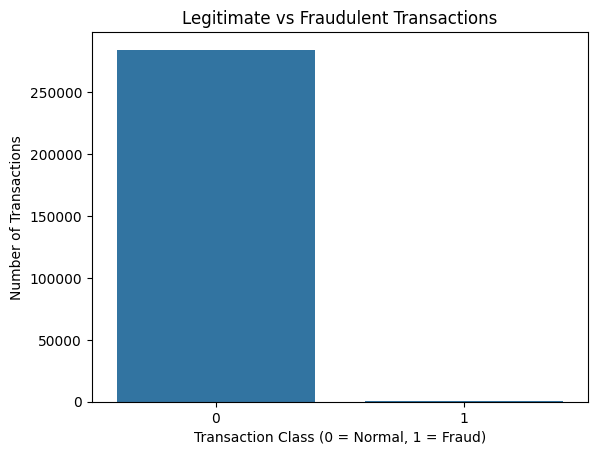

In [34]:
print(df["Class"].value_counts())

sns.countplot(x="Class", data=df)
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

In [35]:
print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates removed successfully!")

Duplicate records: 1081
Duplicates removed successfully!


In [36]:
df["Amount_log"] = np.log1p(df["Amount"])

print(df[["Amount", "Amount_log"]].head())

   Amount  Amount_log
0  149.62    5.014760
1    2.69    1.305626
2  378.66    5.939276
3  123.50    4.824306
4   69.99    4.262539


In [37]:
X = df.drop("Class", axis=1)

y = df["Class"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (283726, 31)
Target: (283726,)


In [38]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (170235, 31)
Validation: (56745, 31)
Testing: (56746, 31)


In [39]:
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train, y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

Before SMOTE:
Class
0    169951
1       284
Name: count, dtype: int64

After SMOTE:
Class
0    169951
1    169951
Name: count, dtype: int64


In [40]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train_balanced, y_train_balanced)

print("Model trained successfully!")

Model trained successfully!


In [41]:
val_prob = model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_threshold = thresholds[np.argmax(f1_scores)]

print("Best Threshold:", best_threshold)

Best Threshold: 0.999999999759839


In [42]:
test_prob = model.predict_proba(X_test)[:, 1]

y_pred = (test_prob >= best_threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, test_prob))

print("PR-AUC:", average_precision_score(y_test, test_prob))

Accuracy: 0.9994360836006062
Precision: 0.8888888888888888
Recall: 0.7578947368421053
F1 Score: 0.8181818181818182
ROC-AUC: 0.9630123126920229
PR-AUC: 0.7466452135543528


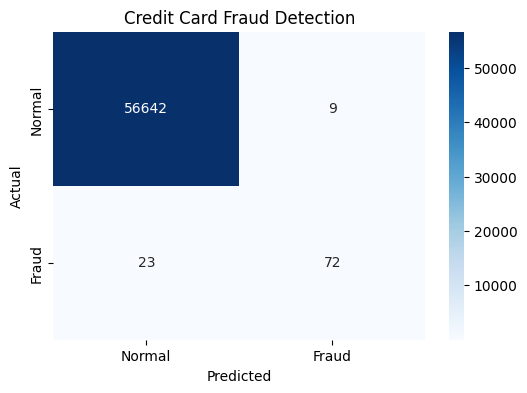

In [43]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("Credit Card Fraud Detection")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

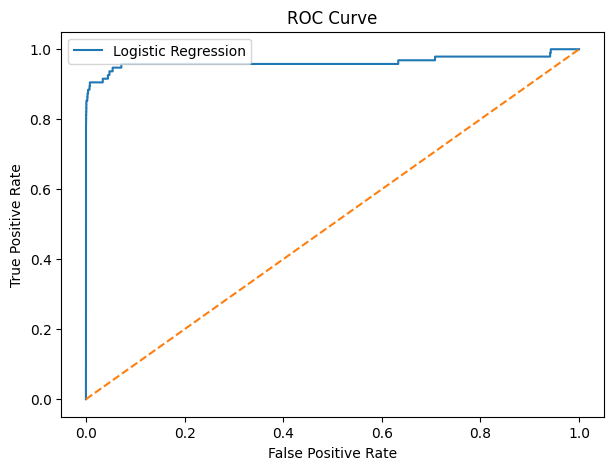

In [44]:
fpr, tpr, thresholds = roc_curve(y_test, test_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label="Logistic Regression")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()
plt.show()

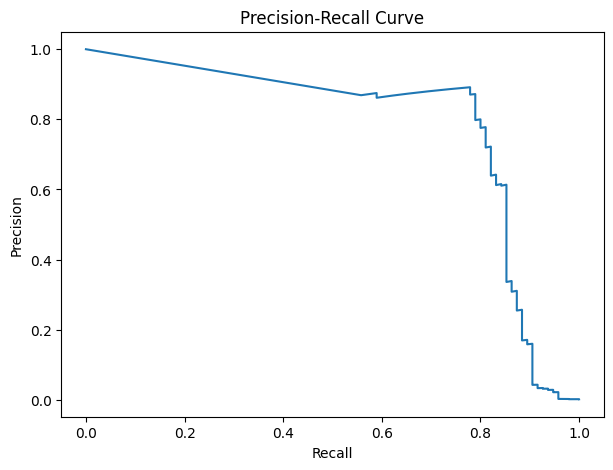

In [45]:
precision, recall, thresholds = precision_recall_curve(
    y_test, test_prob
)

plt.figure(figsize=(7, 5))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.show()

In [46]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [47]:
print("Classification Report")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"]
))

Classification Report
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.89      0.76      0.82        95

    accuracy                           1.00     56746
   macro avg       0.94      0.88      0.91     56746
weighted avg       1.00      1.00      1.00     56746



In [48]:
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC AUC": roc_auc_score(y_test, test_prob),
    "PR AUC": average_precision_score(y_test, test_prob)
}

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Metric", "Score"]
)

results_df.to_csv("fraud_detection_results.csv", index=False)

print(results_df)
print("Results saved successfully!")

      Metric     Score
0   Accuracy  0.999436
1  Precision  0.888889
2     Recall  0.757895
3   F1 Score  0.818182
4    ROC AUC  0.963012
5     PR AUC  0.746645
Results saved successfully!


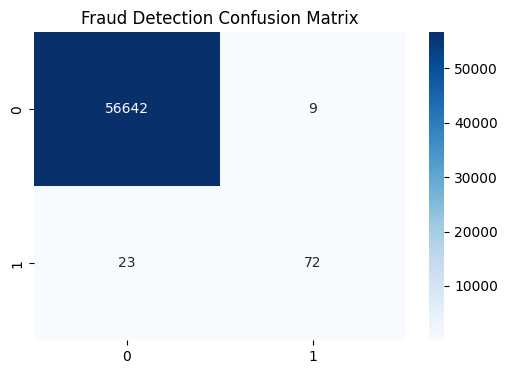

In [49]:
plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Fraud Detection Confusion Matrix")

plt.savefig("confusion_matrix.png")

plt.show()

In [50]:

requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
imbalanced-learn
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")


requirements.txt created successfully!


In [51]:

readme = """# Credit Card Fraud Detection

## Project Overview
This project uses Machine Learning to detect fraudulent credit card transactions.

## Objective
To identify legitimate and fraudulent transactions.

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Imbalanced-learn
- Matplotlib
- Seaborn

## Dataset
Credit Card Fraud Detection Dataset from Kaggle.

## Algorithm
Logistic Regression

## Methodology
1. Data loading
2. Data preprocessing
3. Feature engineering
4. Handling imbalanced data using SMOTE
5. Model training
6. Model evaluation
7. Threshold tuning

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- PR-AUC

## Real World Applications
- Banking security
- Payment fraud detection
- Financial risk management

## Conclusion
This project demonstrates how Machine Learning can help detect fraudulent credit card transactions.
"""

with open("README.md", "w") as file:
    file.write(readme)

print("README.md created successfully!")


README.md created successfully!
